# 🐼 Pandas

**Pandas** — главная библиотека Python для анализа табличных данных.  


**Чему научитесь:**
- Создавать данные (Series, DataFrame) и читать файлы (CSV, Excel)
- Исследовать датасет (head, info, describe, sample)
- Выбирать, фильтровать и сортировать данные
- Работать с пропусками, дубликатами и текстом
- Преобразовывать типы, включая даты и категории
- Группировать, агрегировать и строить сводные таблицы
- Объединять таблицы и менять их форму
- Визуализировать данные и сохранять результаты

**Установка (если нужно):**
```bash
pip install pandas openpyxl matplotlib
```

In [2]:
!pip install pandas

## 1. Импорт и базовая структура: Series

`Series` — это одномерный массив с подписями (индексами). Представьте колонку Excel с именованными ячейками.

In [6]:
import pandas as pd
import numpy as np

print("Версия pandas:", pd.__version__)

# Series из списка
s = pd.Series([10, 20, 30, 40], index=['a', 'b', 'c', 'd'])
print(s)
print("Сумма:", s.sum(), "| Среднее:", s.mean(), "| Максимум:", s.max())

# Математические операции векторизованы — работают над всей колонкой сразу
print("Каждый элемент * 2:")
print(s * 2)

Версия pandas: 2.2.3
a    10
b    20
c    30
d    40
dtype: int64
Сумма: 100 | Среднее: 25.0 | Максимум: 40
Каждый элемент * 2:
a    20
b    40
c    60
d    80
dtype: int64


## 2. DataFrame — таблица из строк и столбцов

Создадим вручную из словаря. На практике чаще загружают из файла.

In [ ]:
df = pd.DataFrame({
    'имя': ['Анна', 'Борис', 'Вера', 'Григорий', 'Дарья'],
    'возраст': [25, 32, 28, 45, 31],
    'город': ['Москва', 'СПб', 'Казань', 'Москва', 'СПб'],
    'зарплата': [90000, 120000, 85000, 150000, 110000],
    'работает': [True, True, False, True, True]
})
df

,имя,возраст,город,зарплата,работает
0,Анна,25,Москва,90000,True
1,Борис,32,СПб,120000,True
2,Вера,28,Казань,85000,False
3,Григорий,45,Москва,150000,True
4,Дарья,31,СПб,110000,True


In [ ]:
# Метаданные таблицы
print("Размер:", df.shape)          # (строки, столбцы)
print("Колонки:", df.columns.tolist())
print("Типы данных:")
print(df.dtypes)

Размер: (5, 5)
Колонки: ['имя', 'возраст', 'город', 'зарплата', 'работает']
Типы данных:
имя         object
возраст      int64
город       object
зарплата     int64
работает      bool
dtype: object


## 3. Загрузка данных из файлов

На практике данные берутся из CSV, Excel, баз данных или API.  
Ниже — загрузка классического датасета «Титаник». Если интернета нет, создадим похожий синтетический набор.

In [7]:
try:
    url = 'https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv'
    titanic = pd.read_csv(url)
    print("✅ Загружено из интернета")
except Exception as e:
    # Запасной вариант без интернета
    rng = np.random.default_rng(42)
    n = 600
    titanic = pd.DataFrame({
        'PassengerId': range(1, n + 1),
        'Survived': rng.integers(0, 2, n),
        'Pclass': rng.integers(1, 4, n),
        'Name': [f'Passenger {i}' for i in range(n)],
        'Sex': rng.choice(['male', 'female'], n),
        'Age': np.round(rng.normal(30, 14, n), 1),
        'SibSp': rng.integers(0, 6, n),
        'Parch': rng.integers(0, 3, n),
        'Fare': np.round(np.abs(rng.normal(50, 40, n)), 2),
        'Embarked': rng.choice(['S', 'C', 'Q'], n),
        'Cabin': np.nan,
    })
    print("⚠️ Сгенерирован локальный датасет (интернета не было)")

print(f"Строк: {titanic.shape[0]}, столбцов: {titanic.shape[1]}")

✅ Загружено из интернета
Строк: 891, столбцов: 12


In [ ]:
# Чтение Excel (требуется openpyxl):
# df_excel = pd.read_excel('data.xlsx', sheet_name='Лист1')

# Основные параметры read_csv:
# pd.read_csv('file.csv', sep=';', encoding='utf-8', decimal=',', nrows=1000)


## 4. Первый взгляд на данные

Всегда начинайте с этих команд — они покажут структуру, проблемы и аномалии.

In [ ]:
# Первые и последние строки
display(titanic.head(3))
display(titanic.tail(2))

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.00,C148,C
890,891,0,3,"Dooley, Mr. Patrick",male,32.0,0,0,370376,7.75,NaN,Q


In [ ]:
# Случайная выборка — чтобы не смотреть только на «верхушку»
titanic.sample(5, random_state=178)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
209,210,1,1,"Blank, Mr. Henry",male,40.0,0,0,112277,31.0000,A31,C
475,476,0,1,"Clifford, Mr. George Quincy",male,NaN,0,0,110465,52.0000,A14,S
274,275,1,3,"Healy, Miss. Hanora ""Nora""",female,NaN,0,0,370375,7.7500,NaN,Q
273,274,0,1,"Natsch, Mr. Charles H",male,37.0,0,1,PC 17596,29.7000,C118,C
410,411,0,3,"Sdycoff, Mr. Todor",male,NaN,0,0,349222,7.8958,NaN,S


In [ ]:
# Типы данных и пропуски
titanic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [ ]:
# Числовая статистика
titanic.describe().round(2)

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.00,891.00,891.00,714.00,891.00,891.00,891.00
mean,446.00,0.38,2.31,29.70,0.52,0.38,32.20
std,257.35,0.49,0.84,14.53,1.10,0.81,49.69
min,1.00,0.00,1.00,0.42,0.00,0.00,0.00
25%,223.50,0.00,2.00,20.12,0.00,0.00,7.91
50%,446.00,0.00,3.00,28.00,0.00,0.00,14.45
75%,668.50,1.00,3.00,38.00,1.00,0.00,31.00
max,891.00,1.00,3.00,80.00,8.00,6.00,512.33


In [ ]:
# Уникальные значения по каждому столбцу (быстрый обзор)
titanic.nunique()

,0
PassengerId,891
Survived,2
Pclass,3
Name,891
Sex,2
Age,88
SibSp,7
Parch,7
Ticket,681
Fare,248


## 5. Индексация: как выбрать данные

Pandas предлагает несколько способов выбора. Главное правило: используйте **один явный метод**, не смешивая их в одной цепочке.

In [ ]:
# [] — быстрый выбор: ОДИН столбец (Series) или список столбцов (DataFrame)
print(type(titanic['Name']))
print(titanic['Name'])      # Series
print(type(titanic[['Name', 'Age']]))  # DataFrame
print(titanic[['Name', 'Age']])
# Но НЕ используйте [] для сложных условий — путаница гарантирована

<class 'pandas.core.series.Series'>
0                                Braund, Mr. Owen Harris
1      Cumings, Mrs. John Bradley (Florence Briggs Th...
2                                 Heikkinen, Miss. Laina
3           Futrelle, Mrs. Jacques Heath (Lily May Peel)
4                               Allen, Mr. William Henry
                             ...                        
886                                Montvila, Rev. Juozas
887                         Graham, Miss. Margaret Edith
888             Johnston, Miss. Catherine Helen "Carrie"
889                                Behr, Mr. Karl Howell
890                                  Dooley, Mr. Patrick
Name: Name, Length: 891, dtype: object
<class 'pandas.core.frame.DataFrame'>
                                                  Name   Age
0                              Braund, Mr. Owen Harris  22.0
1    Cumings, Mrs. John Bradley (Florence Briggs Th...  38.0
2                               Heikkinen, Miss. Laina  26.0
3         Futrel

In [ ]:
# .loc[] — выбор по МЕТКАМ (имена столбцов, метки индекса)
# Включает обе границы среза [0:2] означает 0, 1, 2

titanic.loc[54:333, ['Name', 'Sex', 'Age']]

,Name,Sex
54,"Ostby, Mr. Engelhart Cornelius",male
55,"Woolner, Mr. Hugh",male
56,"Rugg, Miss. Emily",female
57,"Novel, Mr. Mansouer",male
58,"West, Miss. Constance Mirium",female
...,...,...
329,"Hippach, Miss. Jean Gertrude",female
330,"McCoy, Miss. Agnes",female
331,"Partner, Mr. Austen",male
332,"Graham, Mr. George Edward",male


In [ ]:
# .iloc[] — выбор по ПОЗИЦИЯМ (как в numpy)
# НЕ включает правую границу: [0:3] означает 0, 1, 2

titanic.iloc[0:3, 0:5]

,PassengerId,Survived,Pclass,Name,Sex
0,1,0,3,"Braund, Mr. Owen Harris",male
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female
2,3,1,3,"Heikkinen, Miss. Laina",female


In [ ]:
# .at[] и .iat[] — для извлечения ОДНОГО значения (быстрее)
print("Имя первого пассажира:", titanic.at[0, 'Name'])
print("Возраст третьего:", titanic.iat[2, 5])  # позиция столбца Age (зависит от порядка)

Имя первого пассажира: Heikkinen, Miss. Laina
Возраст третьего: 26.0


In [ ]:
# Сброс и установка индекса
# Иногда удобно сделать PassengerId индексом, чтобы не путать с порядковым номером строки

titanic_indexed = titanic.set_index('PassengerId')
print(titanic_indexed.head(2))

# Вернуть индекс в столбец
titanic_indexed.reset_index().head(2)

             Survived  Pclass  \
PassengerId                     
1                   0       3   
2                   1       1   

                                                          Name     Sex   Age  \
PassengerId                                                                    
1                                      Braund, Mr. Owen Harris    male  22.0   
2            Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0   

             SibSp  Parch     Ticket     Fare Cabin Embarked  
PassengerId                                                   
1                1      0  A/5 21171   7.2500   NaN        S  
2                1      0   PC 17599  71.2833   C85        C  


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C


## 6. Фильтрация (условная индексация)

Условие создаёт **маску** — Series из `True/False`. Передав её в `[]`, оставляем только нужные строки.

In [ ]:
# Одиночное условие
mask = titanic['Age'] >= 70
titanic[mask][['Name', 'Age', 'Sex']].head()

,Name,Age,Sex
96,"Goldschmidt, Mr. George B",71.0,male
116,"Connors, Mr. Patrick",70.5,male
493,"Artagaveytia, Mr. Ramon",71.0,male
630,"Barkworth, Mr. Algernon Henry Wilson",80.0,male
672,"Mitchell, Mr. Henry Michael",70.0,male


In [ ]:
# Несколько условий через & (И) и | (ИЛИ)
# Каждое условие ОБЯЗАТЕЛЬНО в скобках!

titanic[(titanic['Sex'] == 'female') & (titanic['Pclass'] == 1)][['Name', 'Age', 'Fare']].head()

,Name,Age,Fare
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",38.0,71.2833
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",35.0,53.1000
11,"Bonnell, Miss. Elizabeth",58.0,26.5500
31,"Spencer, Mrs. William Augustus (Marie Eugenie)",NaN,146.5208
52,"Harper, Mrs. Henry Sleeper (Myna Haxtun)",49.0,76.7292


In [ ]:
# isin — принадлежность списку
# Удобнее, чем цепочка из (x == a) | (x == b)
titanic[titanic['Pclass'].isin([1, 2])].shape

(400, 12)

In [ ]:
# between — диапазон (включительно)
titanic[titanic['Age'].between(25, 25)][['Name', 'Age']].head(3)

,Name,Age
75,"Moen, Mr. Sigurd Hansen",25.0
134,"Sobey, Mr. Samuel James Hayden",25.0
246,"Lindahl, Miss. Agda Thorilda Viktoria",25.0


In [ ]:
# ОБЗОРНО. ВАМ НЕ НАДО
 # query — альтернатива фильтрации, ближе к SQL
# Имена столбцов с пробелами оборачиваются в обратные кавычки

titanic.query("Age > 60 and Pclass == 1")[['Name', 'Age']].head()

,Name,Age
54,"Ostby, Mr. Engelhart Cornelius",65.0
96,"Goldschmidt, Mr. George B",71.0
170,"Van der hoef, Mr. Wyckoff",61.0
252,"Stead, Mr. William Thomas",62.0
275,"Andrews, Miss. Kornelia Theodosia",63.0


In [ ]:
# str.contains — поиск подстроки в тексте
# na=False означает, что NaN не сломают фильтр
# case = Flase игронирует раскладку
titanic[titanic['Name'].str.contains('Osc', case=False, na=False)].head(3)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
25,26,1,3,"Asplund, Mrs. Carl Oscar (Selma Augusta Emilia...",female,38.0,1,5,347077,31.3875,NaN,S
185,186,0,1,"Rood, Mr. Hugh Roscoe",male,NaN,0,0,113767,50.0000,A32,S


In [ ]:
# nlargest / nsmallest — топ-N без сортировки
# Быстрее, чем sort_values().head()
titanic.nlargest(3, 'Fare')[['Name', 'Fare']]

### ⚠️ Важное предупреждение: SettingWithCopyWarning

Когда вы фильтруете DataFrame и пытаетесь изменить результат, Pandas иногда не понимает — это копия или «вид» на оригинал. Всегда делайте `.copy()` перед изменениями.

In [ ]:
# ❌ Плохо — может вызвать предупреждение или баг
#adults = titanic[titanic['Age'] >= 18]
#adults['new_col'] = 1   # SettingWithCopyWarning!

# ✅ Правильно — явная копия
adults = titanic[titanic['Age'] >= 18].copy()
adults['status'] = 'взрослый'
adults.head(8)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,status
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,взрослый
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,взрослый
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,взрослый
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,взрослый
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,взрослый
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S,взрослый
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S,взрослый
11,12,1,1,"Bonnell, Miss. Elizabeth",female,58.0,0,0,113783,26.5500,C103,S,взрослый


## 7. Сортировка

In [ ]:
# По одному столбцу
titanic.sort_values('Fare', ascending=False)[['Name', 'Pclass', 'Fare']].head()

,Name
679,"Cardeza, Mr. Thomas Drake Martinez"
258,"Ward, Miss. Anna"
737,"Lesurer, Mr. Gustave J"
88,"Fortune, Miss. Mabel Helen"
438,"Fortune, Mr. Mark"


In [ ]:
# По нескольким столбцам с разными направлениями
titanic.sort_values(['Age','Sex' ], ascending=[True, False])[['Sex', 'Age']]

,Sex,Age
803,male,0.42
755,male,0.67
469,female,0.75
644,female,0.75
78,male,0.83
...,...,...
727,female,NaN
792,female,NaN
849,female,NaN
863,female,NaN


## 8. Работа с пропусками (NaN)

Пропуски — обычная проблема в реальных данных. Главные инструменты: `isna`, `fillna`, `dropna`, `interpolate`.

In [ ]:
# Сколько пропусков в каждом столбце?
missing = titanic.isna().sum()
missing[missing > 0].sort_values(ascending=False)

,0
Cabin,687
Age,177
Embarked,2


In [ ]:
# Процент пропусков — помогает решить, удалять ли столбец
missing_pct = (titanic.isna().mean() * 100).round(2)
missing_pct[missing_pct > 0]

,0
Age,19.87
Cabin,77.10
Embarked,0.22


In [ ]:
# Заполнение пропусков
# Медиана устойчива к выбросам (в отличие от среднего)
# fillna НЕ меняет исходный DataFrame без присваивания!

titanic['Age'] = titanic['Age'].fillna(titanic['Age'].median())

# Для категориальных — моду (самое частое значение)
most_common_embarked = titanic['Embarked'].mode()[0]
titanic['Embarked'] = titanic['Embarked'].fillna(most_common_embarked)

# Cabin почти весь пустой — удалим столбец
if 'Cabin' in titanic.columns:
    titanic = titanic.drop(columns=['Cabin'])

print(f"Осталось пропусков: {titanic.isna().sum().sum()}")

print(titanic.head(24))

Осталось пропусков: 0
    PassengerId  Survived  Pclass  \
0             1         0       3   
1             2         1       1   
2             3         1       3   
3             4         1       1   
4             5         0       3   
5             6         0       3   
6             7         0       1   
7             8         0       3   
8             9         1       3   
9            10         1       2   
10           11         1       3   
11           12         1       1   
12           13         0       3   
13           14         0       3   
14           15         0       3   
15           16         1       2   
16           17         0       3   
17           18         1       2   
18           19         0       3   
19           20         1       3   
20           21         0       2   
21           22         1       2   
22           23         1       3   
23           24         1       1   

                                                 Nam

In [ ]:
# interpolate — линейная интерполяция (полезна для временных рядов)
# Пример: заполнить пропуски средним соседей
s = pd.Series([1, np.nan, np.nan, 8])
print("Исходная:", s.tolist())
print("Интерполяция:", s.interpolate().tolist())

## 9. Дубликаты

In [ ]:
# Полные дубликаты строк
print("Полных дубликатов:", titanic.duplicated().sum())

# Дубликаты по подмножеству столбцов
print("Дубликатов по полу и классу:", titanic.duplicated(subset=['Sex', 'Pclass']).sum())

# Удаление (keep='first' оставляет первое вхождение)
# titanic = titanic.drop_duplicates(subset=['Name'], keep='first')

Полных дубликатов: 0
Дубликатов по полу и классу: 885


## 10. Типы данных и преобразования

Правильные типы ускоряют операции и экономят память. Особенно важны: `category` и `datetime`.

In [ ]:
# Текущие типы
titanic.dtypes

In [8]:
# Преобразование в категорию — экономит память и ускоряет groupby
titanic['Sex'] = titanic['Sex'].astype('category')
titanic['Pclass'] = titanic['Pclass'].astype('category')
titanic['Embarked'] = titanic['Embarked'].astype('category')

print(titanic[['Sex', 'Pclass', 'Embarked']].dtypes)

Sex         category
Pclass      category
Embarked    category
dtype: object


In [10]:
# Упорядоченная категория (например, для сортировки)
titanic['Pclass'] = pd.Categorical(titanic['Pclass'], categories=[3, 2, 1], ordered=True)
print(titanic['Pclass'].cat.categories)

Index([3, 2, 1], dtype='int64')


In [11]:
# rename — переименование столбцов
titanic = titanic.rename(columns={
    'SibSp': 'siblings_spouses',
    'Parch': 'parents_children'
})
titanic.head(2)

,PassengerId,Survived,Pclass,Name,Sex,Age,siblings_spouses,parents_children,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C


In [12]:
# replace — замена значений
# titanic['Sex'] = titanic['Sex'].replace({'male': 'М', 'female': 'Ж'})

# astype — приведение типов
# titanic['Fare'] = titanic['Fare'].astype('float32')  # экономия памяти

/tmp/ipykernel_926/743271156.py:2: FutureWarning: The behavior of Series.replace (and DataFrame.replace) with CategoricalDtype is deprecated. In a future version, replace will only be used for cases that preserve the categories. To change the categories, use ser.cat.rename_categories instead.
  titanic['Sex'] = titanic['Sex'].replace({'male': 'М', 'female': 'Ж'})


## 11. Работа с датами (datetime)

Даты — отдельный и очень важный тип. Без него невозможна работа с временными рядами.

In [13]:
# Создадим столбец с датой (синтетически, для демонстрации)
titanic['ticket_date'] = pd.to_datetime(
    '1912-04-' + (titanic.index % 10 + 1).astype(str)
)
titanic[['Name', 'ticket_date']].head()

,Name,ticket_date
0,"Braund, Mr. Owen Harris",1912-04-01
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",1912-04-02
2,"Heikkinen, Miss. Laina",1912-04-03
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",1912-04-04
4,"Allen, Mr. William Henry",1912-04-05


In [14]:
# Извлечение компонентов даты
titanic['ticket_month'] = titanic['ticket_date'].dt.month
titanic['ticket_day'] = titanic['ticket_date'].dt.day
titanic['ticket_weekday'] = titanic['ticket_date'].dt.day_name()

titanic[['ticket_date', 'ticket_month', 'ticket_day', 'ticket_weekday']].head()

,ticket_date,ticket_month,ticket_day,ticket_weekday
0,1912-04-01,4,1,Monday
1,1912-04-02,4,2,Tuesday
2,1912-04-03,4,3,Wednesday
3,1912-04-04,4,4,Thursday
4,1912-04-05,4,5,Friday


In [15]:
# Фильтрация по датам (dt accessor)
titanic[titanic['ticket_date'].dt.day > 5].head(2)

,PassengerId,Survived,Pclass,Name,Sex,Age,siblings_spouses,parents_children,Ticket,Fare,Cabin,Embarked,ticket_date,ticket_month,ticket_day,ticket_weekday
5,6,0,3,"Moran, Mr. James",М,NaN,0,0,330877,8.458300,NaN,Q,1912-04-06,4,6,Saturday
6,7,0,1,"McCarthy, Mr. Timothy J",М,54.0,0,0,17463,51.862499,E46,S,1912-04-07,4,7,Sunday


In [16]:
# Разница между датами
reference = pd.Timestamp('1912-04-10')
titanic['days_before'] = (reference - titanic['ticket_date']).dt.days
titanic[['ticket_date', 'days_before']].head()

,ticket_date,days_before
0,1912-04-01,9
1,1912-04-02,8
2,1912-04-03,7
3,1912-04-04,6
4,1912-04-05,5


## 12. Новые столбцы и векторизация

**Золотое правило Pandas:** избегайте `apply` с `axis=1`, если можно сделать векторно — это в 10-100 раз быстрее.

In [ ]:
# ✅ Векторизованные операции — быстро
# titanic['Fare_rub'] = titanic['Fare'] * 90
# titanic['Age_double'] = titanic['Age'] * 2
# titanic['Fare_per_year'] = titanic['Fare'] / titanic['Age']

In [ ]:
# np.where — векторный if/else
# Создадим флаг: дорогой билет (>100) или нет
titanic['is_expensive'] = np.where(titanic['Fare'] > 100, 'дорогой', 'дешёвый')
titanic['is_expensive'].value_counts()

,count
is_expensive,
дешёвый,838
дорогой,53


In [23]:
# np.select — несколько условий (векторный elif)
conditions = [
    titanic['Fare'] < 20,
    titanic['Fare'] < 100,
    titanic['Fare'] < 150
]
choices = ['низкий', 'средний', 'высокий']
titanic['fare_category'] = np.select(conditions, choices, default='неизвестно')
titanic['fare_category'].value_counts()

,count
fare_category,
низкий,515
средний,323
неизвестно,29
высокий,24


In [24]:
# cut — равные интервалы (биннинг)
titanic['age_bin'] = pd.cut(titanic['Age'], bins=[0, 18, 35, 60, 100], labels=['ребёнок', 'молодой', 'взрослый', 'пожилой'])
titanic['age_bin'].value_counts()

,count
age_bin,
молодой,358
взрослый,195
ребёнок,139
пожилой,22


In [25]:
# qcut — квантильные интервалы (по количеству, а не по диапазону)
titanic['fare_quintile'] = pd.qcut(titanic['Fare'], q=5, labels=['Q1', 'Q2', 'Q3', 'Q4', 'Q5'])
titanic['fare_quintile'].value_counts()

,count
fare_quintile,
Q2,184
Q4,180
Q1,179
Q5,176
Q3,172


In [27]:
# apply — только когда векторно невозможно
# Например, сложная логика или работа со строками посимвольно

def extract_title(name):
    if 'Mr.' in name: return 'Mr9399939'
    if 'Mrs.' in name: return 'Mrs3332'
    if 'Miss.' in name: return 'Miss11123233'
    return 'Other'

# apply к Series (один столбец) — медленнее вектора, но допустимо
titanic['title'] = titanic['Name'].apply(extract_title)
titanic['title'].value_counts().head()

,count
title,
Mr9399939,517
Miss11123233,182
Mrs3332,125
Other,67


In [ ]:
# Строковые методы через .str (векторизованы!)
titanic['Name_upper'] = titanic['Name'].str.upper()
titanic['Name_short'] = titanic['Name'].str[:10]
titanic[['Name', 'Name_upper', 'Name_short']].head(2)

## 13. Группировка и агрегация

`groupby` разбивает данные на группы, агрегирует каждую и собирает результат.

In [ ]:
# Простая агрегация: средняя цена билета по классам
titanic.groupby('Pclass')['Fare'].mean().round(2)

In [28]:
# agg — несколько функций сразу, с новыми именами
titanic.groupby('Sex').agg(
    count=('Name', 'count'),
    avg_age=('Age', 'mean'),
    max_fare=('Fare', 'max'),
    survived_rate=('Survived', 'mean')
).round(2)

/tmp/ipykernel_926/1893809699.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  titanic.groupby('Sex').agg(


,count,avg_age,max_fare,survived_rate
Sex,,,,
Ж,314,27.92,512.330017,0.74
М,577,30.73,512.330017,0.19


In [29]:
# Группировка по двум столбцам + несколько метрик
titanic.groupby(['Sex', 'Pclass']).agg(
    n=('Name', 'count'),
    avg_fare=('Fare', 'mean')
).round(2)

/tmp/ipykernel_926/1895584833.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  titanic.groupby(['Sex', 'Pclass']).agg(


n    avg_fare
Sex Pclass                 
Ж   3       144   16.120001
    2        76   21.969999
    1        94  106.129997
М   3       347   12.660000
    2       108   19.740000
    1       122   67.230003

In [30]:
# transform — агрегация «без потери строк»
# Например: добавить столбец со средним возрастом по полу для КАЖДОЙ строки

titanic['avg_age_by_sex'] = titanic.groupby('Sex')['Age'].transform('mean').round(1)
titanic[['Sex', 'Age', 'avg_age_by_sex']].head()

/tmp/ipykernel_926/814009605.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  titanic['avg_age_by_sex'] = titanic.groupby('Sex')['Age'].transform('mean').round(1)


,Sex,Age,avg_age_by_sex
0,М,22.0,30.7
1,Ж,38.0,27.9
2,Ж,26.0,27.9
3,Ж,35.0,27.9
4,М,35.0,30.7


In [32]:
# filter — отфильтровать группы по условию
# Оставить только те группы (по полу), где средняя цена билета > 50

titanic.groupby('Sex').filter(lambda x: x['Fare'].mean() > 20).head(3)

/tmp/ipykernel_926/1100619536.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  titanic.groupby('Sex').filter(lambda x: x['Fare'].mean() > 20).head(3)


,PassengerId,Survived,Pclass,Name,Sex,Age,siblings_spouses,parents_children,Ticket,Fare,...,ticket_date,ticket_month,ticket_day,ticket_weekday,days_before,fare_category,age_bin,fare_quintile,title,avg_age_by_sex
0,1,0,3,"Braund, Mr. Owen Harris",М,22.0,1,0,A/5 21171,7.250000,...,1912-04-01,4,1,Monday,9,низкий,молодой,Q1,Mr9399939,30.7
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",Ж,38.0,1,0,PC 17599,71.283302,...,1912-04-02,4,2,Tuesday,8,средний,взрослый,Q5,Mrs3332,27.9
2,3,1,3,"Heikkinen, Miss. Laina",Ж,26.0,0,0,STON/O2. 3101282,7.925000,...,1912-04-03,4,3,Wednesday,7,низкий,молодой,Q2,Miss11123233,27.9


In [33]:
# value_counts — самая частая агрегация
# normalize=True возвращает доли
titanic['Embarked'].value_counts(normalize=True).round(3)

,proportion
Embarked,
S,0.724
C,0.189
Q,0.087


## 14. Сводные таблицы и кросстабуляция

In [ ]:
# pivot_table — сводная таблица
# Средняя выживаемость: строки — пол, столбцы — класс
titanic.pivot_table(values='Survived', index='Sex', columns='Pclass', aggfunc='mean').round(2)

In [ ]:
# margins — итоги по строкам и столбцам
titanic.pivot_table(values='Survived', index='Sex', columns='Pclass', aggfunc='mean', margins=True).round(2)

In [ ]:
# crosstab — частотная таблица (под капотом pivot_table)
# Часто удобнее для подсчётов
pd.crosstab(titanic['Sex'], titanic['Pclass'], margins=True)

In [ ]:
# crosstab с нормализацией (доли)
pd.crosstab(titanic['Sex'], titanic['Pclass'], normalize='index').round(2)

## 15. Изменение формы таблиц: melt и pivot

In [34]:
# melt — широкий формат → длинный (wide → long)
# Полезно для визуализации и последующего groupby

wide = titanic.head(3)[['Name', 'Age', 'Fare']]
print("Wide:")
display(wide)

long = wide.melt(id_vars=['Name'], var_name='metric', value_name='value')
print("Long:")
display(long)

Wide:


,Name,Age,Fare
0,"Braund, Mr. Owen Harris",22.0,7.250000
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",38.0,71.283302
2,"Heikkinen, Miss. Laina",26.0,7.925000


Long:


,Name,metric,value
0,"Braund, Mr. Owen Harris",Age,22.000000
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",Age,38.000000
2,"Heikkinen, Miss. Laina",Age,26.000000
3,"Braund, Mr. Owen Harris",Fare,7.250000
4,"Cumings, Mrs. John Bradley (Florence Briggs Th...",Fare,71.283302
5,"Heikkinen, Miss. Laina",Fare,7.925000


In [ ]:
# pivot — длинный формат → широкий (обратная операция)
long.pivot(index='Name', columns='metric', values='value').reset_index()

## 16. Объединение таблиц

Аналоги SQL JOIN: `merge` (по ключу) и `concat` (склейка).

In [35]:
# merge — JOIN по ключу
ports = pd.DataFrame({
    'code': ['S', 'C', 'Q'],
    'port_name': ['Саутгемптон', 'Шербур', 'Квинстаун'],
    'country': ['UK', 'France', 'Ireland']
})
ports

,code,port_name,country
0,S,Саутгемптон,UK
1,C,Шербур,France
2,Q,Квинстаун,Ireland


In [37]:
titanic["Embarked"]


,Embarked
0,S
1,C
2,S
3,S
4,S
...,...
886,S
887,S
888,S
889,C


In [38]:
# how='left' — как SQL LEFT JOIN (сохраняем все строки левой таблицы)
titanic = titanic.merge(ports, left_on='Embarked', right_on='code', how='left')
titanic[['Name', 'Embarked', 'port_name', 'country']].head()

,Name,Embarked,port_name,country
0,"Braund, Mr. Owen Harris",S,Саутгемптон,UK
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",C,Шербур,France
2,"Heikkinen, Miss. Laina",S,Саутгемптон,UK
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",S,Саутгемптон,UK
4,"Allen, Mr. William Henry",S,Саутгемптон,UK


In [ ]:
# concat — склейка
# axis=0 (по умолчанию) — друг под другом, axis=1 — рядом (горизонтально)

top = titanic.head(2)
bottom = titanic.tail(2)
pd.concat([top, bottom], axis=0)

## 17. Визуализация средствами Pandas

Pandas строит графики через matplotlib. Для анализа — быстро и удобно.

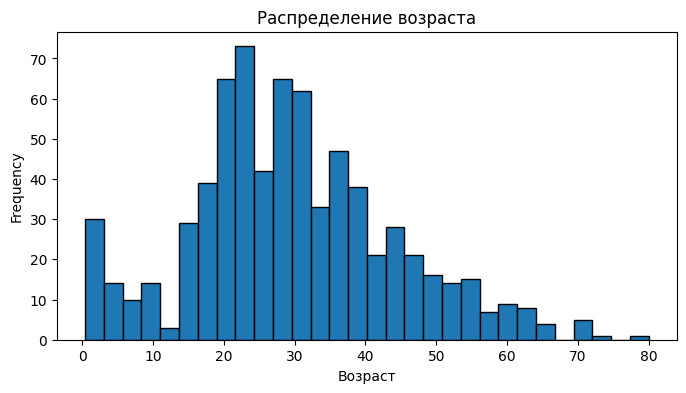

In [39]:
import matplotlib.pyplot as plt
plt.rcParams['figure.figsize'] = (8, 4)

# Гистограмма
titanic['Age'].plot.hist(bins=30, edgecolor='black', title='Распределение возраста')
plt.xlabel('Возраст')
plt.show()

/tmp/ipykernel_926/1238736115.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  titanic.groupby('Pclass')['Survived'].mean().plot.bar(


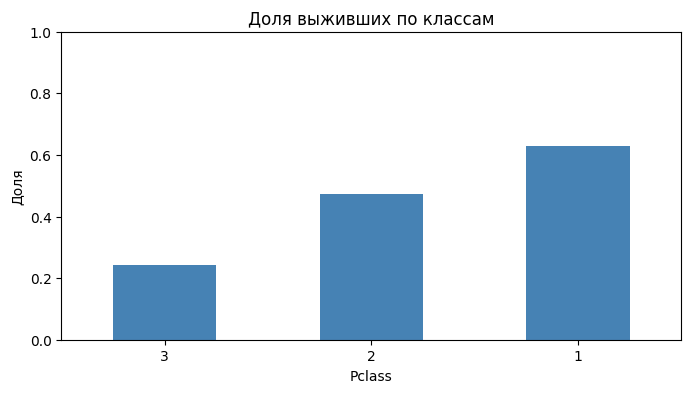

In [40]:
# Столбчатая диаграмма
titanic.groupby('Pclass')['Survived'].mean().plot.bar(
    title='Доля выживших по классам', ylabel='Доля', rot=0, color='steelblue')
plt.ylim(0, 1)
plt.show()

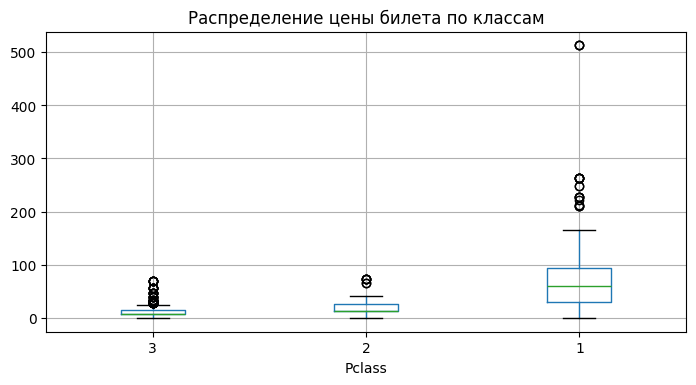

In [41]:
# Boxplot — распределение цены по классам
titanic.boxplot(column='Fare', by='Pclass')
plt.suptitle('')  # убрать автоматический заголовок
plt.title('Распределение цены билета по классам')
plt.show()

In [42]:
# Корреляционная матрица (только числовые столбцы)
numeric_cols = titanic.select_dtypes(include='number').columns
corr = titanic[numeric_cols].corr()
corr.style.background_gradient(cmap='coolwarm', vmin=-1, vmax=1).format("{:.2f}")

,PassengerId,Survived,Age,siblings_spouses,parents_children,Fare,ticket_month,ticket_day,days_before,avg_age_by_sex
PassengerId,1.00,-0.01,0.04,-0.06,-0.00,0.01,nan,0.01,-0.01,0.04
Survived,-0.01,1.00,-0.08,-0.04,0.08,0.26,nan,0.07,-0.07,-0.54
Age,0.04,-0.08,1.00,-0.31,-0.19,0.10,nan,0.01,-0.01,0.09
siblings_spouses,-0.06,-0.04,-0.31,1.00,0.41,0.16,nan,-0.03,0.03,-0.11
parents_children,-0.00,0.08,-0.19,0.41,1.00,0.22,nan,0.05,-0.05,-0.25
Fare,0.01,0.26,0.10,0.16,0.22,1.00,nan,0.08,-0.08,-0.18
ticket_month,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
ticket_day,0.01,0.07,0.01,-0.03,0.05,0.08,nan,1.00,-1.00,-0.06
days_before,-0.01,-0.07,-0.01,0.03,-0.05,-0.08,nan,-1.00,1.00,0.06
avg_age_by_sex,0.04,-0.54,0.09,-0.11,-0.25,-0.18,nan,-0.06,0.06,1.00


## 18. Сохранение результатов

In [43]:
# CSV — универсальный формат
titanic.to_csv('titanic_clean.csv', index=False)

# Excel — удобно для коллег
titanic.to_excel('titanic_clean.xlsx', index=False, sheet_name='Passengers')

# Без индекса — чтобы не создавать лишний unnamed столбец при повторном чтении
print("Сохранено!")

Сохранено!


## 19. Продвинутые приёмы и best practices

In [44]:
# 1. Метод-цепочка (method chaining) — читаемый код без промежуточных переменных
result = (
    titanic
    .assign(Fare_rub=lambda df: df['Fare'] * 90)
    .query("Age >= 18")
    .groupby('Sex')
    .agg(avg_fare=('Fare_rub', 'mean'), count=('Name', 'count'))
    .round(2)
)
result

/tmp/ipykernel_926/3985172975.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby('Sex')


,avg_fare,count
Sex,,
Ж,4638.080078,206
М,2421.540039,395


In [ ]:
# 2. pipe — применение своей функции в цепочке

def log_shape(df, label):
    print(f"{label}: {df.shape}")
    return df

result = (
    titanic
    .pipe(log_shape, 'Начало')
    .query("Fare > 10")
    .pipe(log_shape, 'После фильтра')
)

In [ ]:
# 3. memory_usage — оценка потребления памяти
print(titanic.memory_usage(deep=True).sum() / 1024, "KB")

# Сравнение: object vs category
# object: ~KB, category: ~0.5 KB для этого столбца

In [ ]:
# 4. Итерация — последний курорт
# Никогда НЕ делайте: for i in range(len(df)): ...
# Если без цикла никак — используйте iterrows или itertuples (быстрее)

for idx, row in titanic.head(2).iterrows():
    print(f"{row['Name']}: {row['Age']} лет")

## 🎓 Шпаргалка

| Задача | Код |
|---|---|
| Прочитать CSV | `pd.read_csv('file.csv')` |
| Прочитать Excel | `pd.read_excel('file.xlsx')` |
| Первые строки | `df.head(n)` |
| Случайная выборка | `df.sample(n)` |
| Инфо о данных | `df.info()` |
| Статистика | `df.describe()` |
| Уникальные значения | `df.nunique()` |
| Выбор по меткам | `df.loc[rows, cols]` |
| Выбор по позициям | `df.iloc[rows, cols]` |
| Отфильтровать | `df[df['col'] > 5]` |
| Фильтр SQL-style | `df.query("col > 5")` |
| Отсортировать | `df.sort_values('col')` |
| Топ-N | `df.nlargest(5, 'col')` |
| Найти пропуски | `df.isna().sum()` |
| Заполнить пропуски | `df['col'].fillna(0)` |
| Удалить дубликаты | `df.drop_duplicates()` |
| Переименовать столбцы | `df.rename(columns={'old':'new'})` |
| Сменить тип | `df['col'].astype('category')` |
| Даты | `pd.to_datetime(df['col'])` |
| Новый столбец | `df['new'] = df['a'] * 2` |
| Векторный if/else | `np.where(cond, a, b)` |
| Биннинг | `pd.cut(df['col'], bins=...)` |
| Группировка | `df.groupby('col')['val'].mean()` |
| Агрегация | `df.groupby('col').agg(x=('val','mean'))` |
| Сводная таблица | `df.pivot_table(...)` |
| Частотная таблица | `pd.crosstab(a, b)` |
| Широкий → длинный | `df.melt(...)` |
| Соединить таблицы | `df1.merge(df2, on='key')` |
| Склеить таблицы | `pd.concat([df1, df2])` |
| Сохранить CSV | `df.to_csv('out.csv', index=False)` |

## 🏋️ Задачи для практики

1. Найдите самого молодого и самого старшего пассажира (`idxmin`, `idxmax`).
2. Посчитайте средний возраст выживших и погибших.
3. Определите, какой порт посадки (`Embarked`) давал самую высокую выживаемость.
4. Создайте столбец `FamilySize = siblings_spouses + parents_children + 1` и сравните выживаемость для одиночек (`FamilySize == 1`) и семей.

_______________________________________________________________________________
5. Сделать join таблиц с именами портов. Вывести всех людей кто сел в порту "Шербур"
6. **Средний:** Используя `cut`, разбейте пассажиров на 4 возрастные группы и посчитайте выживаемость в каждой.
7. **Средний:** С помощью `pivot_table` постройте таблицу: строки — `Sex`, столбцы — `Pclass`, значения — средняя `Fare`.
8. **Продвинутый:** Найдите «аномалии»: пассажиров третьего класса, старше 20 и младше 40 лет  заплативших больше среднего людей из второго класса.
9. **Продвинутый:** Создайте столбец `deck` из первой буквы `Cabin` (если `Cabin` есть в данных). Посчитайте выживаемость по палубам.
10. Сделайте разбивку людей по диапазонам возрастов и посчитайте отношение в данных  (value_counts)  (cut [0, 18, 35, 60, 100])


In [ ]:
a = titanic.sort_values('Age')['Age']
print(a.head(1).index)
print(a.tail(1).index)

b = titanic['Age'].idxmin()
dd = titanic['Age'].idxmax()
print(b)
print(dd)

Index([803], dtype='int64')
Index([630], dtype='int64')
803
630


In [ ]:
print(titanic[titanic['Survived']==1]['Age'].mean())
print(titanic[titanic['Survived']==0]['Age'].mean())

28.29143274853801
30.028233151183972


In [ ]:
titanic.groupby('Embarked')['Survived'].mean().round(2)

,Survived
Embarked,
C,0.55
Q,0.39
S,0.34
